# Setup and shared data

In [1]:
from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
import json
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

from torch.utils.data import Dataset, DataLoader, Subset
from torchvision import datasets, transforms
from torchvision.utils import make_grid, save_image
from tqdm.auto import tqdm

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

PROJECT_DIR = Path("/content/drive/MyDrive/DDPM")
OUT_DIR = PROJECT_DIR / "baselines_all"
OUT_DIR.mkdir(parents=True, exist_ok=True)

reference = torch.load(
    PROJECT_DIR / "ddpm_cosine_epoch_200.pt",
    map_location="cpu",
    weights_only=True
)

LATENT_DIM = 128

train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize((0.5,) * 3, (0.5,) * 3)
])

val_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,) * 3, (0.5,) * 3)
])

train_source = datasets.CIFAR10(
    root=str(PROJECT_DIR / "data"),
    train=True,
    download=True,
    transform=train_transform
)

val_source = datasets.CIFAR10(
    root=str(PROJECT_DIR / "data"),
    train=True,
    download=False,
    transform=val_transform
)

train_data = Subset(train_source, reference["train_indices"])
val_data = Subset(val_source, reference["val_indices"])

def make_train_loader():
    return DataLoader(
        train_data,
        batch_size=32,
        shuffle=True,
        num_workers=0,
        pin_memory=(device.type == "cuda"),
        generator=torch.Generator().manual_seed(42)
    )

val_loader = DataLoader(
    val_data,
    batch_size=64,
    shuffle=False,
    num_workers=0
)

def save_checkpoint(payload, path):
    temporary = path.with_suffix(".tmp")
    torch.save(payload, temporary)
    temporary.replace(path)

print("Device:", device)
print("Training images:", len(train_data))
print("Validation images:", len(val_data))

Mounted at /content/drive
Device: cuda
Training images: 45000
Validation images: 5000


# Define AE and VAE

In [ ]:
class Encoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(3, 32, 4, 2, 1),
            nn.ReLU(),
            nn.Conv2d(32, 64, 4, 2, 1),
            nn.ReLU(),
            nn.Conv2d(64, 128, 4, 2, 1),
            nn.ReLU(),
            nn.Flatten()
        )

    def forward(self, x):
        return self.net(x)


class Decoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc = nn.Linear(LATENT_DIM, 128 * 4 * 4)
        self.net = nn.Sequential(
            nn.ConvTranspose2d(128, 64, 4, 2, 1),
            nn.ReLU(),
            nn.ConvTranspose2d(64, 32, 4, 2, 1),
            nn.ReLU(),
            nn.ConvTranspose2d(32, 3, 4, 2, 1),
            nn.Tanh()
        )

    def forward(self, z):
        return self.net(self.fc(z).reshape(-1, 128, 4, 4))


class Autoencoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = Encoder()
        self.latent = nn.Linear(128 * 4 * 4, LATENT_DIM)
        self.decoder = Decoder()

    def forward(self, x):
        return self.decoder(self.latent(self.encoder(x)))


class VAE(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = Encoder()
        self.mu = nn.Linear(128 * 4 * 4, LATENT_DIM)
        self.logvar = nn.Linear(128 * 4 * 4, LATENT_DIM)
        self.decoder = Decoder()

    def forward(self, x):
        features = self.encoder(x)
        mu = self.mu(features)
        logvar = self.logvar(features)

        z = mu + torch.exp(0.5 * logvar) * torch.randn_like(mu)

        return self.decoder(z), mu, logvar

# Train AE and VAE with automatic resumption

In [ ]:
def train_autoencoder(name, target_epochs=50):
    torch.manual_seed(42)

    model = (
        Autoencoder() if name == "ae" else VAE()
    ).to(device)

    optimizer = torch.optim.Adam(model.parameters(), lr=2e-4)
    path = OUT_DIR / f"{name}_latest.pt"

    history = []
    completed = 0

    if path.is_file():
        saved = torch.load(
            path, map_location="cpu", weights_only=True
        )
        assert saved["train_indices"] == reference["train_indices"]
        assert saved["val_indices"] == reference["val_indices"]
        assert saved["latent_dim"] == LATENT_DIM

        model.load_state_dict(saved["model"])
        optimizer.load_state_dict(saved["optimizer"])
        history = saved["history"]
        completed = saved["epoch"]

        print(f"{name.upper()}: restored epoch {completed}")

    loader = make_train_loader()

    for epoch in range(completed + 1, target_epochs + 1):
        model.train()
        total = 0.0
        count = 0

        for images, _ in tqdm(
            loader, desc=f"{name.upper()} {epoch}/{target_epochs}"
        ):
            images = images.to(device)
            optimizer.zero_grad(set_to_none=True)

            if name == "ae":
                output = model(images)
                loss = F.mse_loss(output, images)
            else:
                output, mu, logvar = model(images)

                reconstruction = (
                    (output - images).square()
                    .flatten(1).sum(1).mean()
                )

                kl = -0.5 * (
                    1 + logvar - mu.square() - logvar.exp()
                ).sum(1).mean()

                loss = reconstruction + kl

            if not torch.isfinite(loss):
                raise RuntimeError(f"Non-finite {name} loss.")

            loss.backward()
            optimizer.step()

            total += loss.item() * images.size(0)
            count += images.size(0)

        history.append(total / count)

        save_checkpoint({
            "epoch": epoch,
            "model": model.state_dict(),
            "optimizer": optimizer.state_dict(),
            "history": history,
            "latent_dim": LATENT_DIM,
            "train_indices": reference["train_indices"],
            "val_indices": reference["val_indices"]
        }, path)

        completed = epoch
        print(f"Mean loss: {history[-1]:.6f}")

    return model, history, completed

In [ ]:
ae_model, ae_history, ae_epoch = train_autoencoder(
    "ae", target_epochs=50
)

AE: restored epoch 50


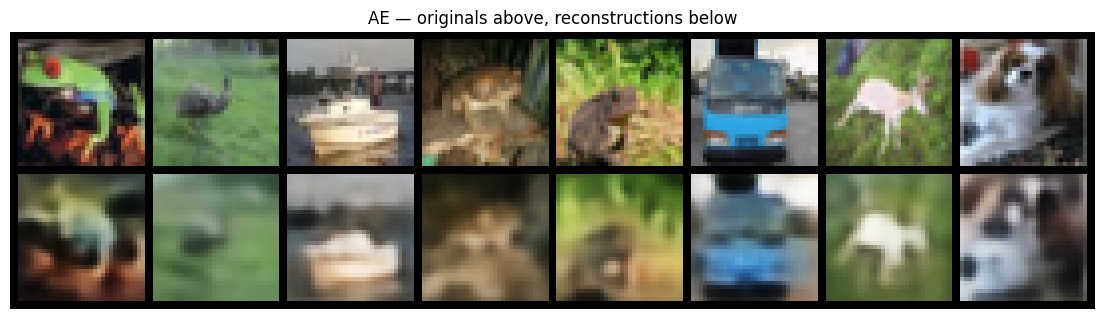

In [ ]:
import matplotlib.pyplot as plt
from torchvision.utils import make_grid, save_image

images, _ = next(iter(val_loader))
images = images[:8].to(device)

with torch.no_grad():
    reconstructed = ae_model(images)

comparison_images = (
    (torch.cat([images, reconstructed]) + 1) / 2
).clamp(0, 1).cpu()

grid = make_grid(
    comparison_images,
    nrow=8,
    padding=2
)

plt.figure(figsize=(14, 4))
plt.imshow(grid.permute(1, 2, 0).numpy())
plt.title("AE — originals above, reconstructions below")
plt.axis("off")
plt.show()

save_image(
    comparison_images,
    OUT_DIR / "ae_reconstructions.png",
    nrow=8,
    padding=2
)

In [ ]:
# AE and VAE loss magnitudes are not directly comparable: their objectives and reductions differ.
vae_model, vae_history, vae_epoch = train_autoencoder(
    "vae", target_epochs=50
)

VAE: restored epoch 50


# Define DCGAN

In [ ]:
class Generator(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.ConvTranspose2d(LATENT_DIM, 256, 4, 1, 0, bias=False),
            nn.BatchNorm2d(256),
            nn.ReLU(),

            nn.ConvTranspose2d(256, 128, 4, 2, 1, bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU(),

            nn.ConvTranspose2d(128, 64, 4, 2, 1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(),

            nn.ConvTranspose2d(64, 3, 4, 2, 1, bias=False),
            nn.Tanh()
        )

    def forward(self, z):
        return self.net(z[:, :, None, None])


class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(3, 64, 4, 2, 1, bias=False),
            nn.LeakyReLU(0.2),

            nn.Conv2d(64, 128, 4, 2, 1, bias=False),
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2),

            nn.Conv2d(128, 256, 4, 2, 1, bias=False),
            nn.BatchNorm2d(256),
            nn.LeakyReLU(0.2),

            nn.Conv2d(256, 1, 4, 1, 0, bias=False)
        )

    def forward(self, x):
        return self.net(x).flatten()


def initialize_gan(module):
    if isinstance(module, (nn.Conv2d, nn.ConvTranspose2d)):
        nn.init.normal_(module.weight, 0, 0.02)
    elif isinstance(module, nn.BatchNorm2d):
        nn.init.normal_(module.weight, 1, 0.02)
        nn.init.zeros_(module.bias)

# Train DCGAN with automatic resumption

In [ ]:
def train_dcgan(target_epochs=50):
    torch.manual_seed(42)

    generator = Generator().to(device)
    discriminator = Discriminator().to(device)

    generator.apply(initialize_gan)
    discriminator.apply(initialize_gan)

    optimizer_g = torch.optim.Adam(
        generator.parameters(), lr=2e-4, betas=(0.5, 0.999)
    )
    optimizer_d = torch.optim.Adam(
        discriminator.parameters(), lr=2e-4, betas=(0.5, 0.999)
    )

    criterion = nn.BCEWithLogitsLoss()
    path = OUT_DIR / "dcgan_latest.pt"
    history = []
    completed = 0

    if path.is_file():
        saved = torch.load(
            path, map_location="cpu", weights_only=True
        )
        assert saved["train_indices"] == reference["train_indices"]
        assert saved["val_indices"] == reference["val_indices"]
        assert saved["latent_dim"] == LATENT_DIM

        generator.load_state_dict(saved["generator"])
        discriminator.load_state_dict(saved["discriminator"])
        optimizer_g.load_state_dict(saved["optimizer_g"])
        optimizer_d.load_state_dict(saved["optimizer_d"])

        history = saved["history"]
        completed = saved["epoch"]

        print("DCGAN: restored epoch", completed)

    fixed_z = torch.randn(
        16, LATENT_DIM,
        generator=torch.Generator().manual_seed(123)
    ).to(device)

    loader = make_train_loader()

    for epoch in range(completed + 1, target_epochs + 1):
        generator.train()
        discriminator.train()

        total_g = total_d = 0.0
        count = 0

        for real, _ in tqdm(
            loader, desc=f"DCGAN {epoch}/{target_epochs}"
        ):
            real = real.to(device)
            size = real.size(0)

            # Discriminator update
            discriminator.requires_grad_(True)
            optimizer_d.zero_grad(set_to_none=True)

            z = torch.randn(size, LATENT_DIM, device=device)
            fake = generator(z)

            loss_d = (
                criterion(
                    discriminator(real),
                    torch.ones(size, device=device)
                )
                + criterion(
                    discriminator(fake.detach()),
                    torch.zeros(size, device=device)
                )
            )

            if not torch.isfinite(loss_d):
                raise RuntimeError("Non-finite discriminator loss.")

            loss_d.backward()
            optimizer_d.step()

            # Generator update
            discriminator.requires_grad_(False)
            optimizer_g.zero_grad(set_to_none=True)

            loss_g = criterion(
                discriminator(fake),
                torch.ones(size, device=device)
            )

            if not torch.isfinite(loss_g):
                raise RuntimeError("Non-finite generator loss.")

            loss_g.backward()
            optimizer_g.step()
            discriminator.requires_grad_(True)

            total_g += loss_g.item() * size
            total_d += loss_d.item() * size
            count += size

        history.append({
            "generator": total_g / count,
            "discriminator": total_d / count
        })

        save_checkpoint({
            "epoch": epoch,
            "generator": generator.state_dict(),
            "discriminator": discriminator.state_dict(),
            "optimizer_g": optimizer_g.state_dict(),
            "optimizer_d": optimizer_d.state_dict(),
            "history": history,
            "latent_dim": LATENT_DIM,
            "train_indices": reference["train_indices"],
            "val_indices": reference["val_indices"]
        }, path)

        generator.eval()
        with torch.no_grad():
            samples = ((generator(fixed_z) + 1) / 2).clamp(0, 1)

        save_image(
            samples,
            OUT_DIR / f"dcgan_epoch_{epoch}_seed123.png",
            nrow=4
        )

        completed = epoch
        print(history[-1])

    return generator, history, completed

In [ ]:
gan_model, gan_history, gan_epoch = train_dcgan(
    target_epochs=50
)

print("DCGAN completed epoch:", gan_epoch)

DCGAN: restored epoch 3


DCGAN 4/50:   0%|          | 0/1407 [00:00<?, ?it/s]

{'generator': 2.653291098605262, 'discriminator': 0.6819396549330817}


DCGAN 5/50:   0%|          | 0/1407 [00:00<?, ?it/s]

{'generator': 2.736816505347358, 'discriminator': 0.6394783151255714}


...

{'generator': 4.037596138289239, 'discriminator': 0.33656279729207356}


DCGAN 49/50:   0%|          | 0/1407 [00:00<?, ?it/s]

{'generator': 4.04911992685712, 'discriminator': 0.3402680122998026}


DCGAN 50/50:   0%|          | 0/1407 [00:00<?, ?it/s]

{'generator': 4.135699351526632, 'discriminator': 0.3429958940585454}
DCGAN completed epoch: 50


# Display and save results

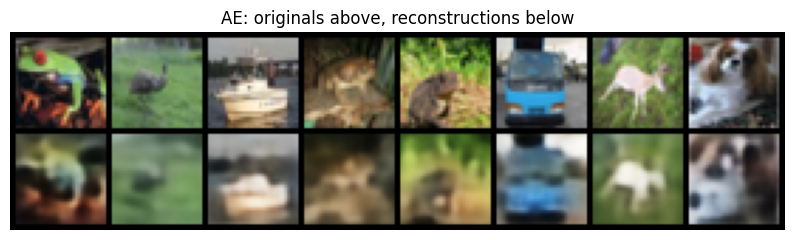

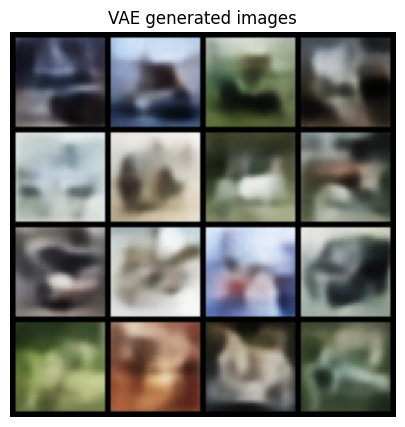

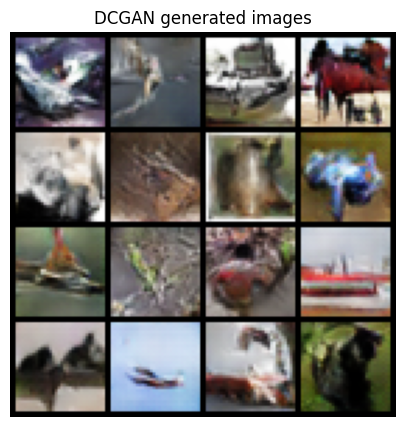

In [ ]:
def display_grid(images, title, filename, nrow=4):
    images = images.detach().cpu().clamp(0, 1)

    save_image(images, OUT_DIR / filename, nrow=nrow)

    grid = make_grid(images, nrow=nrow)

    plt.figure(figsize=(10, 5))
    plt.imshow(grid.permute(1, 2, 0).numpy())
    plt.title(title)
    plt.axis("off")
    plt.show()


ae_model.eval()
vae_model.eval()
gan_model.eval()

images, _ = next(iter(val_loader))
images = images[:8].to(device)

with torch.no_grad():
    reconstructed = ae_model(images)

    display_grid(
        (torch.cat([images, reconstructed]) + 1) / 2,
        "AE: originals above, reconstructions below",
        "ae_reconstructions.png",
        nrow=8
    )

    z = torch.randn(
        16, LATENT_DIM,
        generator=torch.Generator().manual_seed(123)
    ).to(device)

    display_grid(
        (vae_model.decoder(z) + 1) / 2,
        "VAE generated images",
        "vae_samples.png"
    )

    display_grid(
        (gan_model(z) + 1) / 2,
        "DCGAN generated images",
        "dcgan_samples.png"
    )

# Evaluate AE reconstruction quality

In [ ]:
ae_model.eval()
total_squared_error = 0.0
total_pixels = 0

with torch.no_grad():
    for images, _ in val_loader:
        images = images.to(device)
        reconstructed = ae_model(images)

        total_squared_error += F.mse_loss(
            reconstructed, images, reduction="sum"
        ).item()

        total_pixels += images.numel()

ae_results = {
    "model": "AE",
    "epoch": ae_epoch,
    "validation_reconstruction_mse": (
        total_squared_error / total_pixels
    ),
    "pixel_range": [-1, 1]
}

with open(OUT_DIR / f"ae_epoch_{ae_epoch}_metrics.json", "w") as file:
    json.dump(ae_results, file, indent=2)

print(ae_results)

{'model': 'AE', 'epoch': 50, 'validation_reconstruction_mse': 0.01753691477775574, 'pixel_range': [-1, 1]}


# Evaluate VAE and DCGAN with FID/Inception Score

In [ ]:
%pip install -q torch-fidelity

In [ ]:
import torch_fidelity


class ImageTensorDataset(Dataset):
    def __init__(self, images):
        self.images = images

    def __len__(self):
        return len(self.images)

    def __getitem__(self, index):
        return self.images[index]


# Original uint8 validation images
real_uint8 = torch.from_numpy(
    val_source.data[reference["val_indices"]].copy()
).permute(0, 3, 1, 2).contiguous()


@torch.no_grad()
def evaluate_generator(model, name, trained_epoch):
    model.eval()

    prefix = f"{name}_epoch_{trained_epoch}"
    images_path = OUT_DIR / f"{prefix}_evaluation_images.pt"
    results_path = OUT_DIR / f"{prefix}_metrics.json"

    if results_path.is_file():
        with open(results_path) as file:
            return json.load(file)

    num_samples = 5000
    assert len(real_uint8) >= num_samples

    if images_path.is_file():
        fake_uint8 = torch.load(
            images_path, map_location="cpu", weights_only=True
        )
    else:
        batches = []

        for start in tqdm(
            range(0, num_samples, 32),
            desc=f"Sampling {name}"
        ):
            size = min(32, num_samples - start)

            z = torch.randn(
                size, LATENT_DIM,
                generator=torch.Generator().manual_seed(10000 + start)
            ).to(device)

            output = (
                model.decoder(z)
                if name == "vae"
                else model(z)
            )

            samples = ((output + 1) / 2).clamp(0, 1)

            batches.append(
                (samples * 255).round().to(torch.uint8).cpu()
            )

        fake_uint8 = torch.cat(batches)
        torch.save(fake_uint8, images_path)

    assert len(fake_uint8) == num_samples

    metrics = torch_fidelity.calculate_metrics(
        input1=ImageTensorDataset(fake_uint8),
        input2=ImageTensorDataset(real_uint8[:num_samples]),
        cuda=(device.type == "cuda"),
        batch_size=64,
        fid=True,
        isc=True,
        kid=False,
        verbose=True
    )

    report = {
        "model": name,
        "epoch": trained_epoch,
        "num_generated_images": num_samples,
        "num_real_images": num_samples,
        **{key: float(value) for key, value in metrics.items()}
    }

    with open(results_path, "w") as file:
        json.dump(report, file, indent=2)

    return report

In [ ]:
vae_results = evaluate_generator(
    vae_model, "vae", vae_epoch
)
print(vae_results)

Sampling vae:   0%|          | 0/157 [00:00<?, ?it/s]

Creating feature extractor "inception-v3-compat" with features ['logits_unbiased', '2048']
Downloading: "https://github.com/toshas/torch-fidelity/releases/download/v0.2.0/weights-inception-2015-12-05-6726825d.pth" to /root/.cache/torch/hub/checkpoints/weights-inception-2015-12-05-6726825d.pth
100%|██████████| 91.2M/91.2M [00:00<00:00, 103MB/s]
Extracting features from input1
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
Processing samples:   0%|          | 0/5000 [00:00<?, ?samples/s]/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:432: Us

{'model': 'vae', 'epoch': 50, 'num_generated_images': 5000, 'num_real_images': 5000, 'inception_score_mean': 3.344376717018053, 'inception_score_std': 0.07755675596487797, 'frechet_inception_distance': 136.20542746497557}


Frechet Inception Distance: 136.2054


In [ ]:
gan_results = evaluate_generator(
    gan_model, "dcgan", gan_epoch
)
print(gan_results)

Sampling dcgan:   0%|          | 0/157 [00:00<?, ?it/s]

Creating feature extractor "inception-v3-compat" with features ['logits_unbiased', '2048']
Extracting features from input1
Processing samples
Extracting features from input2
Processing samples
Inception Score: 6.310348 ± 0.2223442


{'model': 'dcgan', 'epoch': 50, 'num_generated_images': 5000, 'num_real_images': 5000, 'inception_score_mean': 6.310347874105799, 'inception_score_std': 0.22234418719371918, 'frechet_inception_distance': 44.659938173586}


Frechet Inception Distance: 44.65994


# Compare generated-image metrics with DDPM

In [ ]:
import pandas as pd

with open(PROJECT_DIR / "cosine_epoch_200_metrics.json") as file:
    cosine_results = json.load(file)

with open(PROJECT_DIR / "linear_epoch_200_metrics.json") as file:
    linear_results = json.load(file)

comparison = pd.DataFrame([
    {
        "Model": name,
        "Epoch": result["epoch"],
        "FID": result["frechet_inception_distance"],
        "Inception Score": result["inception_score_mean"],
        "IS std": result["inception_score_std"]
    }
    for name, result in [
        ("VAE", vae_results),
        ("DCGAN", gan_results),
        ("Cosine DDPM", cosine_results),
        ("Linear DDPM", linear_results)
    ]
])

display(comparison)

comparison.to_csv(
    OUT_DIR / "generative_model_comparison.csv",
    index=False
)

,Model,Epoch,FID,Inception Score,IS std
0,VAE,50,136.205427,3.344377,0.077557
1,DCGAN,50,44.659938,6.310348,0.222344
2,Cosine DDPM,200,39.954588,6.820897,0.277831
3,Linear DDPM,200,39.074490,6.557743,0.279640


VAE: Highest FID and lowest IS, consistent with the blurry samples observed.
DCGAN: Better scores than VAE, but behind both DDPMs.
Cosine DDPM: Highest IS; its FID is slightly higher than linear DDPM.
Linear DDPM: Lowest FID, making it the preferred model if FID is your primary criterion.

# Preserve the epoch-50 checkpoints

In [ ]:
import shutil
import torch

for name in ["ae", "vae", "dcgan"]:
    source = OUT_DIR / f"{name}_latest.pt"

    saved = torch.load(
        source,
        map_location="cpu",
        weights_only=True
    )

    epoch = saved["epoch"]
    destination = OUT_DIR / f"{name}_epoch_{epoch}.pt"

    if not destination.exists():
        shutil.copy2(source, destination)

    print(f"{name.upper()}: preserved epoch {epoch}")

AE: preserved epoch 50
VAE: preserved epoch 50
DCGAN: preserved epoch 50


# Train for 50 additional epochs

In [ ]:
ae_model, ae_history, ae_epoch = train_autoencoder(
    "ae",
    target_epochs=100
)

AE: restored epoch 50


AE 51/100:   0%|          | 0/1407 [00:00<?, ?it/s]

Mean loss: 0.017138


AE 52/100:   0%|          | 0/1407 [00:00<?, ?it/s]

Mean loss: 0.017125


...

Mean loss: 0.016717


AE 99/100:   0%|          | 0/1407 [00:00<?, ?it/s]

Mean loss: 0.016718


AE 100/100:   0%|          | 0/1407 [00:00<?, ?it/s]

Mean loss: 0.016715


In [ ]:
vae_model, vae_history, vae_epoch = train_autoencoder(
    "vae",
    target_epochs=100
)

VAE: restored epoch 50


VAE 51/100:   0%|          | 0/1407 [00:00<?, ?it/s]

Mean loss: 180.692479


VAE 52/100:   0%|          | 0/1407 [00:00<?, ?it/s]

Mean loss: 180.624667


...

Mean loss: 178.878887


VAE 99/100:   0%|          | 0/1407 [00:00<?, ?it/s]

Mean loss: 178.835774


VAE 100/100:   0%|          | 0/1407 [00:00<?, ?it/s]

Mean loss: 178.872552


In [ ]:
gan_model, gan_history, gan_epoch = train_dcgan(
    target_epochs=100
)

DCGAN: restored epoch 50


DCGAN 51/100:   0%|          | 0/1407 [00:00<?, ?it/s]

{'generator': 4.104052822166019, 'discriminator': 0.3129968821350071}


DCGAN 52/100:   0%|          | 0/1407 [00:00<?, ?it/s]

{'generator': 4.1616094491640725, 'discriminator': 0.3113532200468911}


...

{'generator': 5.024489441299439, 'discriminator': 0.2125560628571444}


DCGAN 99/100:   0%|          | 0/1407 [00:00<?, ?it/s]

{'generator': 5.000130924108293, 'discriminator': 0.2424485989547438}


DCGAN 100/100:   0%|          | 0/1407 [00:00<?, ?it/s]

{'generator': 5.0456093117607965, 'discriminator': 0.20936139418457944}


# Compare AE validation MSE at epochs 50 and 100

In [ ]:
import pandas as pd
import torch.nn.functional as F

def evaluate_ae_checkpoint(path):
    saved = torch.load(
        path,
        map_location="cpu",
        weights_only=True
    )

    model = Autoencoder().to(device)
    model.load_state_dict(saved["model"])
    model.eval()

    total_error = 0.0
    total_pixels = 0

    with torch.no_grad():
        for images, _ in val_loader:
            images = images.to(device)
            reconstructed = model(images)

            total_error += F.mse_loss(
                reconstructed,
                images,
                reduction="sum"
            ).item()

            total_pixels += images.numel()

    return {
        "Model": "AE",
        "Epoch": saved["epoch"],
        "Validation reconstruction MSE": total_error / total_pixels
    }


ae_comparison = pd.DataFrame([
    evaluate_ae_checkpoint(OUT_DIR / "ae_epoch_50.pt"),
    evaluate_ae_checkpoint(OUT_DIR / "ae_latest.pt")
])

display(ae_comparison)

ae_comparison.to_csv(
    OUT_DIR / "ae_epoch_50_vs_100.csv",
    index=False
)

,Model,Epoch,Validation reconstruction MSE
0,AE,50,0.017537
1,AE,100,0.017323


# Evaluate VAE and DCGAN at epoch 100

In [ ]:
vae_results_100 = evaluate_generator(
    vae_model,
    "vae",
    vae_epoch
)

print(vae_results_100)

Sampling vae:   0%|          | 0/157 [00:00<?, ?it/s]

Creating feature extractor "inception-v3-compat" with features ['logits_unbiased', '2048']
Extracting features from input1
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
Processing samples:   0%|          | 0/5000 [00:00<?, ?samples/s]/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoad

{'model': 'vae', 'epoch': 100, 'num_generated_images': 5000, 'num_real_images': 5000, 'inception_score_mean': 3.426021313224492, 'inception_score_std': 0.1317596718081312, 'frechet_inception_distance': 133.77426331560332}


Frechet Inception Distance: 133.7743


In [ ]:
gan_results_100 = evaluate_generator(
    gan_model,
    "dcgan",
    gan_epoch
)

print(gan_results_100)

Sampling dcgan:   0%|          | 0/157 [00:00<?, ?it/s]

Creating feature extractor "inception-v3-compat" with features ['logits_unbiased', '2048']
Extracting features from input1
Processing samples
Extracting features from input2
Processing samples
Inception Score: 6.354316 ± 0.2135289


{'model': 'dcgan', 'epoch': 100, 'num_generated_images': 5000, 'num_real_images': 5000, 'inception_score_mean': 6.354315893541435, 'inception_score_std': 0.21352890812569977, 'frechet_inception_distance': 42.92292362378197}


Frechet Inception Distance: 42.92292


# Compare epochs 50 and 100 with DDPM results

In [ ]:
import json

rows = []

for name in ["vae", "dcgan"]:
    for epoch in [50, 100]:
        path = OUT_DIR / f"{name}_epoch_{epoch}_metrics.json"

        if not path.is_file():
            print("Missing evaluation:", path.name)
            continue

        with open(path) as file:
            result = json.load(file)

        rows.append({
            "Model": name.upper(),
            "Epoch": result["epoch"],
            "FID": result["frechet_inception_distance"],
            "Inception Score": result["inception_score_mean"],
            "IS std": result["inception_score_std"],
            "Real images": result["num_real_images"],
            "Generated images": result["num_generated_images"]
        })

for name in ["cosine", "linear"]:
    with open(
        PROJECT_DIR / f"{name}_epoch_200_metrics.json"
    ) as file:
        result = json.load(file)

    rows.append({
        "Model": f"{name.capitalize()} DDPM",
        "Epoch": result["epoch"],
        "FID": result["frechet_inception_distance"],
        "Inception Score": result["inception_score_mean"],
        "IS std": result["inception_score_std"],
        "Real images": result["num_real_images"],
        "Generated images": result["num_generated_images"]
    })

comparison = pd.DataFrame(rows)

assert comparison["Real images"].eq(5000).all()
assert comparison["Generated images"].eq(5000).all()

display(comparison)

comparison.to_csv(
    OUT_DIR / "baseline_epoch_comparison.csv",
    index=False
)

,Model,Epoch,FID,Inception Score,IS std,Real images,Generated images
0,VAE,50,136.205427,3.344377,0.077557,5000,5000
1,VAE,100,133.774263,3.426021,0.131760,5000,5000
2,DCGAN,50,44.659938,6.310348,0.222344,5000,5000
3,DCGAN,100,42.922924,6.354316,0.213529,5000,5000
4,Cosine DDPM,200,39.954588,6.820897,0.277831,5000,5000
5,Linear DDPM,200,39.074490,6.557743,0.279640,5000,5000


In [ ]:
#preserve 100 epoch checkpoints
for name in ["vae", "dcgan"]:
    source = OUT_DIR / f"{name}_latest.pt"
    destination = OUT_DIR / f"{name}_epoch_100.pt"

    saved = torch.load(
        source, map_location="cpu", weights_only=True
    )

    assert saved["epoch"] == 100

    if not destination.exists():
        shutil.copy2(source, destination)

In [ ]:
vae_model, vae_history, vae_epoch = train_autoencoder(
    "vae",
    target_epochs=200
)

VAE: restored epoch 100


VAE 101/200:   0%|          | 0/1407 [00:00<?, ?it/s]

Mean loss: 178.689113


VAE 102/200:   0%|          | 0/1407 [00:00<?, ?it/s]

Mean loss: 178.685135


...

Mean loss: 177.474100


VAE 199/200:   0%|          | 0/1407 [00:00<?, ?it/s]

Mean loss: 177.572000


VAE 200/200:   0%|          | 0/1407 [00:00<?, ?it/s]

Mean loss: 177.462169


In [ ]:
gan_model, gan_history, gan_epoch = train_dcgan(
    target_epochs=200
)

DCGAN: restored epoch 100


DCGAN 101/200:   0%|          | 0/1407 [00:00<?, ?it/s]

{'generator': 5.078133342573378, 'discriminator': 0.2117039538949728}


DCGAN 102/200:   0%|          | 0/1407 [00:00<?, ?it/s]

{'generator': 5.083343109128211, 'discriminator': 0.22471596002843644}


...

{'generator': 6.092552698389689, 'discriminator': 0.16505848002541396}


DCGAN 199/200:   0%|          | 0/1407 [00:00<?, ?it/s]

{'generator': 6.0807156200938755, 'discriminator': 0.15287437192400297}


DCGAN 200/200:   0%|          | 0/1407 [00:00<?, ?it/s]

{'generator': 5.981340110015869, 'discriminator': 0.1443253444156713}


In [ ]:
vae_results_200 = evaluate_generator(
    vae_model, "vae", vae_epoch
)

Sampling vae:   0%|          | 0/157 [00:00<?, ?it/s]

Creating feature extractor "inception-v3-compat" with features ['logits_unbiased', '2048']
Extracting features from input1
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
Processing samples:   0%|          | 0/5000 [00:00<?, ?samples/s]/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoad

In [ ]:
gan_results_200 = evaluate_generator(
    gan_model, "dcgan", gan_epoch
)

Sampling dcgan:   0%|          | 0/157 [00:00<?, ?it/s]

Creating feature extractor "inception-v3-compat" with features ['logits_unbiased', '2048']
Extracting features from input1
Processing samples
Extracting features from input2
Processing samples
Inception Score: 6.613271 ± 0.1744837
Frechet Inception Distance: 39.61683


In [ ]:
import pandas as pd
PROJECT_DIR = Path("/content/drive/MyDrive/DDPM")
OUT_DIR = PROJECT_DIR / "baselines_all"
OUT_DIR.mkdir(parents=True, exist_ok=True)

rows = []


def add_result(path, model_name):
    with open(path) as file:
        result = json.load(file)

    rows.append({
        "Model": model_name,
        "Epoch": result["epoch"],
        "FID": result["frechet_inception_distance"],
        "Inception Score": result["inception_score_mean"],
        "IS std": result["inception_score_std"],
        "Real images": result["num_real_images"],
        "Generated images": result["num_generated_images"]
    })


# VAE and DCGAN: epochs 50, 100, 200
for name in ["vae", "dcgan"]:
    for epoch in [50, 100, 200]:
        path = OUT_DIR / f"{name}_epoch_{epoch}_metrics.json"

        if not path.is_file():
            print("Missing results:", path.name)
            continue

        add_result(path, name.upper())


# DDPMs with attention
for schedule in ["cosine", "linear"]:
    add_result(
        PROJECT_DIR / f"{schedule}_epoch_200_metrics.json",
        f"{schedule.capitalize()} DDPM + attention"
    )


# Linear DDPM without attention
add_result(
    PROJECT_DIR / "linear_no_attention/metrics_epoch_200.json",
    "Linear DDPM without attention"
)


comparison = pd.DataFrame(rows)

assert comparison["Real images"].eq(5000).all(), (
    "Real-image counts must all equal 5,000."
)

assert comparison["Generated images"].eq(5000).all(), (
    "Generated-image counts must all equal 5,000."
)

print("All recorded epochs:")
display(comparison.round(4))

print("\nEpoch-200 comparison:")
final_comparison = (
    comparison[comparison["Epoch"] == 200]
    .sort_values("FID")
    .reset_index(drop=True)
)

display(final_comparison.round(4))

comparison.to_csv(
    OUT_DIR / "all_epochs_comparison.csv",
    index=False
)

final_comparison.to_csv(
    OUT_DIR / "epoch_200_model_comparison.csv",
    index=False
)

print("\nComparison tables saved.")

All recorded epochs:


,Model,Epoch,FID,Inception Score,IS std,Real images,Generated images
0,VAE,50,136.2054,3.3444,0.0776,5000,5000
1,VAE,100,133.7743,3.4260,0.1318,5000,5000
2,VAE,200,132.6878,3.4810,0.0897,5000,5000
3,DCGAN,50,44.6599,6.3103,0.2223,5000,5000
4,DCGAN,100,42.9229,6.3543,0.2135,5000,5000
5,DCGAN,200,39.6168,6.6133,0.1745,5000,5000
6,Cosine DDPM + attention,200,39.9546,6.8209,0.2778,5000,5000
7,Linear DDPM + attention,200,39.0745,6.5577,0.2796,5000,5000
8,Linear DDPM without attention,200,52.3218,5.6041,0.1767,5000,5000



Epoch-200 comparison:


,Model,Epoch,FID,Inception Score,IS std,Real images,Generated images
0,Linear DDPM + attention,200,39.0745,6.5577,0.2796,5000,5000
1,DCGAN,200,39.6168,6.6133,0.1745,5000,5000
2,Cosine DDPM + attention,200,39.9546,6.8209,0.2778,5000,5000
3,Linear DDPM without attention,200,52.3218,5.6041,0.1767,5000,5000
4,VAE,200,132.6878,3.4810,0.0897,5000,5000



Comparison tables saved.


### Final Model Comparison — 200 Epochs

| Model | FID ↓ | Inception Score ↑ | Observation |
|---|---:|---:|---|
| Linear DDPM + attention | 39.07 | 6.56 | Lowest FID among the evaluated models. |
| DCGAN | 39.62 | 6.61 | Competitive with both attention-enabled DDPMs. |
| Cosine DDPM + attention | 39.95 | 6.82 | Highest Inception Score. |
| Linear DDPM without attention | 52.32 | 5.60 | Worse FID and IS than linear DDPM with attention. |
| VAE | 132.69 | 3.48 | Highest FID and lowest IS among the evaluated models. |

### Attention Ablation

With the linear schedule held constant, adding attention:

- Reduced FID from **52.32 to 39.07**, an improvement of approximately **25.3%**.
- Increased Inception Score from **5.60 to 6.56**.

These results support the benefit of attention in this experiment.
Repeated training runs would be needed to establish a consistent effect.

### Noise-Schedule Comparison

With attention retained:

- Linear achieved slightly lower FID: **39.07 vs. 39.95**.
- Cosine achieved slightly higher IS: **6.82 vs. 6.56**.
- Neither schedule was best on both metrics.

### Effect of Additional Training

- **DCGAN:** FID improved from **44.66 at epoch 50 to 39.62 at epoch 200**.
- **VAE:** FID improved modestly from **136.21 to 132.69**.
- Both models also showed increases in Inception Score.

### Conclusion and Limitations

Linear DDPM with attention is preferred when **FID is the primary
selection criterion**. Cosine DDPM achieved the highest IS, while DCGAN
remained competitive.

All final models trained for **200 epochs** and were evaluated using
**5,000 real and 5,000 generated images**. Equal epochs do not imply
equal computational cost.

These are single-run results. Small differences among DCGAN and the
attention-enabled DDPMs should not be treated as definitive superiority.
IS standard deviation describes variation across evaluation splits,
not across independent training runs.

AE reconstruction MSE is reported separately because reconstruction
and unconditional generation are different tasks.

### Improving the Cosine DDPM with EMA

The cosine-schedule DDPM achieved an FID of **39.95** and an Inception
Score of **6.82** after 200 epochs. Its FID is above the aspirational
range mentioned in the project brief. The published benchmark used a
different training and evaluation setup, so the scores are not directly
equivalent.

The saved epoch-200 cosine model will be trained for 50 additional
epochs. An Exponential Moving Average (EMA) of model weights will be
initialized from the epoch-200 checkpoint and updated after every
optimizer step.

At epoch 250, regular and EMA weights will be evaluated using the same
validation split, 5,000 generated images, sampling process, and
FID/Inception Score implementation as the epoch-200 baseline.

EMA begins at epoch 200; it does not average weights from the first
200 epochs. Additional training and EMA may improve sample quality,
but improvement is not guaranteed.

# Prepare the same data

In [ ]:
PROJECT_DIR = Path("/content/drive/MyDrive/DDPM")
EMA_DIR = PROJECT_DIR / "cosine_ema_from_epoch_200"
EMA_DIR.mkdir(parents=True, exist_ok=True)

baseline_path = PROJECT_DIR / "ddpm_cosine_epoch_200.pt"
latest_path = EMA_DIR / "cosine_ema_latest.pt"

baseline = torch.load(
    baseline_path,
    map_location="cpu",
    weights_only=True
)

assert baseline["epoch"] == 200
assert baseline["schedule"] == "cosine"

train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize((0.5,) * 3, (0.5,) * 3)
])

train_source = datasets.CIFAR10(
    root=str(PROJECT_DIR / "data"),
    train=True,
    download=True,
    transform=train_transform
)

train_data = Subset(
    train_source,
    baseline["train_indices"]
)

train_loader = DataLoader(
    train_data,
    batch_size=32,
    shuffle=True,
    num_workers=0,
    pin_memory=(device.type == "cuda"),
    generator=torch.Generator().manual_seed(42)
)

print("Device:", device)
print("Training images:", len(train_data))

# Restore cosine model and initialize EMA

In [ ]:
EMA_DECAY = 0.999
TARGET_EPOCH = 400

model = DiffusionUNet(
    **baseline["model_config"]
).to(device)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=2e-4,
    weight_decay=0.0
)

if latest_path.is_file():
    saved = torch.load(
        latest_path,
        map_location="cpu",
        weights_only=True
    )

    assert saved["schedule"] == "cosine"
    assert saved["model_config"] == baseline["model_config"]
    assert saved["train_indices"] == baseline["train_indices"]
    assert saved["val_indices"] == baseline["val_indices"]
    assert torch.equal(
        saved["betas"].cpu(),
        baseline["betas"].cpu()
    )

    model.load_state_dict(saved["model_state_dict"])
    optimizer.load_state_dict(saved["optimizer_state_dict"])

    ema_model = copy.deepcopy(model)
    ema_model.load_state_dict(saved["ema_state_dict"])

    ema_decay = saved["ema_decay"]
    completed_epoch = saved["epoch"]
    loss_history = list(saved["loss_history"])

    print("Resumed from epoch:", completed_epoch)

else:
    model.load_state_dict(baseline["model_state_dict"])
    optimizer.load_state_dict(baseline["optimizer_state_dict"])

    ema_model = copy.deepcopy(model)

    ema_decay = EMA_DECAY
    completed_epoch = 200
    loss_history = list(baseline.get("loss_history", []))

    print("EMA initialized from cosine epoch 200.")

ema_model.eval()
ema_model.requires_grad_(False)

# Use the exact cosine schedule saved during original training
betas = baseline["betas"].to(device)
alpha_bars = torch.cumprod(1.0 - betas, dim=0)
timesteps = len(betas)

print("Next epoch:", completed_epoch + 1)

# Define EMA update and checkpoint saving

In [ ]:
@torch.no_grad()
def update_ema(ema_model, model, decay):
    for ema_parameter, parameter in zip(
        ema_model.parameters(),
        model.parameters()
    ):
        ema_parameter.mul_(decay).add_(
            parameter,
            alpha=1.0 - decay
        )

    for ema_buffer, buffer in zip(
        ema_model.buffers(),
        model.buffers()
    ):
        ema_buffer.copy_(buffer)


def save_cosine_ema_checkpoint(epoch_number):
    payload = {
        "epoch": epoch_number,
        "ema_start_epoch": 200,
        "ema_decay": ema_decay,
        "model_config": baseline["model_config"],
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "ema_state_dict": ema_model.state_dict(),
        "schedule": "cosine",
        "timesteps": timesteps,
        "betas": betas.detach().cpu(),
        "loss_history": loss_history,
        "train_indices": baseline["train_indices"],
        "val_indices": baseline["val_indices"]
    }

    temporary_path = EMA_DIR / "cosine_ema_latest.tmp"

    torch.save(payload, temporary_path)
    temporary_path.replace(latest_path)

    if epoch_number == TARGET_EPOCH:
        torch.save(
            payload,
            EMA_DIR / f"cosine_ema_epoch_{epoch_number}.pt"
        )

# Train epochs 201–400

In [ ]:
for epoch in range(completed_epoch + 1, TARGET_EPOCH + 1):
    model.train()

    total_loss = 0.0
    total_images = 0

    progress = tqdm(
        train_loader,
        desc=f"Cosine + EMA {epoch}/{TARGET_EPOCH}"
    )

    for images, _ in progress:
        images = images.to(device, non_blocking=True)

        t = torch.randint(
            0,
            timesteps,
            (images.size(0),),
            device=device
        )

        target_noise = torch.randn_like(images)
        alpha_bar = alpha_bars[t].view(-1, 1, 1, 1)

        noisy_images = (
            alpha_bar.sqrt() * images
            + (1.0 - alpha_bar).sqrt() * target_noise
        )

        optimizer.zero_grad(set_to_none=True)

        predicted_noise = model(noisy_images, t)

        loss = F.mse_loss(
            predicted_noise,
            target_noise
        )

        if not torch.isfinite(loss):
            raise RuntimeError("Non-finite loss detected.")

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        optimizer.step()

        # EMA must be updated after every optimizer step
        update_ema(ema_model, model, ema_decay)

        total_loss += loss.item() * images.size(0)
        total_images += images.size(0)

        progress.set_postfix(mse=f"{loss.item():.4f}")

    epoch_loss = total_loss / total_images
    loss_history.append(epoch_loss)

    save_cosine_ema_checkpoint(epoch)
    completed_epoch = epoch

    print(f"Epoch {epoch}: mean MSE = {epoch_loss:.6f}")

print("Completed epoch:", completed_epoch)

# Compare generated samples

In [ ]:
regular_samples = generate_samples(
    model,
    baseline["betas"],
    num_images=16,
    seed=123
)

ema_samples = generate_samples(
    ema_model,
    baseline["betas"],
    num_images=16,
    seed=123
)

fig, axes = plt.subplots(1, 2, figsize=(12, 6))

for ax, samples, title in zip(
    axes,
    [regular_samples, ema_samples],
    ["Cosine epoch 250 — regular", "Cosine epoch 250 — EMA"]
):
    grid = make_grid(samples, nrow=4, padding=2)

    ax.imshow(grid.permute(1, 2, 0).cpu().numpy())
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()

plt.savefig(
    EMA_DIR / "regular_vs_ema_samples_epoch_250.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

save_image(
    regular_samples,
    EMA_DIR / "regular_epoch_250_seed123.png",
    nrow=4
)

save_image(
    ema_samples,
    EMA_DIR / "ema_epoch_250_seed123.png",
    nrow=4
)

# Evaluate regular and EMA weights

In [ ]:
class ImageTensorDataset(Dataset):
    def __init__(self, images):
        self.images = images

    def __len__(self):
        return len(self.images)

    def __getitem__(self, index):
        return self.images[index]


real_source = datasets.CIFAR10(
    root=str(PROJECT_DIR / "data"),
    train=True,
    download=True
)

real_uint8 = torch.from_numpy(
    real_source.data[
        baseline["val_indices"]
    ].copy()
).permute(0, 3, 1, 2).contiguous()

NUM_SAMPLES = 5000
GENERATION_BATCH_SIZE = 32

assert len(real_uint8) >= NUM_SAMPLES

In [ ]:
def evaluate_cosine_weights(eval_model, label):
    assert completed_epoch == TARGET_EPOCH, (
        "Complete epoch 250 before evaluation."
    )

    image_path = (
        EMA_DIR / f"{label}_epoch_250_evaluation_images.pt"
    )

    result_path = (
        EMA_DIR / f"{label}_epoch_250_metrics.json"
    )

    if result_path.is_file():
        with open(result_path) as file:
            return json.load(file)

    if image_path.is_file():
        fake_uint8 = torch.load(
            image_path,
            map_location="cpu",
            weights_only=True
        )

    else:
        batches = []

        for start in tqdm(
            range(0, NUM_SAMPLES, GENERATION_BATCH_SIZE),
            desc=f"Generating {label} images"
        ):
            batch_size = min(
                GENERATION_BATCH_SIZE,
                NUM_SAMPLES - start
            )

            samples = generate_samples(
                eval_model,
                baseline["betas"],
                num_images=batch_size,
                seed=10000 + start,
                show_progress=False
            )

            batches.append(
                (samples * 255)
                .round()
                .clamp(0, 255)
                .to(torch.uint8)
            )

        fake_uint8 = torch.cat(batches, dim=0)
        torch.save(fake_uint8, image_path)

    assert len(fake_uint8) == NUM_SAMPLES

    metrics = torch_fidelity.calculate_metrics(
        input1=ImageTensorDataset(fake_uint8),
        input2=ImageTensorDataset(real_uint8[:NUM_SAMPLES]),
        cuda=(device.type == "cuda"),
        batch_size=64,
        fid=True,
        isc=True,
        kid=False,
        verbose=True
    )

    report = {
        "experiment": label,
        "schedule": "cosine",
        "epoch": TARGET_EPOCH,
        "ema_start_epoch": 200 if label == "ema" else None,
        "ema_decay": ema_decay if label == "ema" else None,
        "num_real_images": NUM_SAMPLES,
        "num_generated_images": NUM_SAMPLES,
        "generation_batch_size": GENERATION_BATCH_SIZE,
        **{
            key: float(value)
            for key, value in metrics.items()
        }
    }

    with open(result_path, "w") as file:
        json.dump(report, file, indent=2)

    return report

In [ ]:
regular_results = evaluate_cosine_weights(model, "regular")
print(regular_results)

In [ ]:
ema_results = evaluate_cosine_weights(ema_model, "ema")
print(ema_results)

# Compare against your epoch-200 cosine baseline

In [ ]:
with open(PROJECT_DIR / "cosine_epoch_200_metrics.json") as file:
    baseline_results = json.load(file)

for result in [baseline_results, regular_results, ema_results]:
    assert result["num_real_images"] == 5000
    assert result["num_generated_images"] == 5000

comparison = pd.DataFrame([
    {
        "Model": name,
        "Epoch": result["epoch"],
        "FID": result["frechet_inception_distance"],
        "Inception Score": result["inception_score_mean"],
        "IS std": result["inception_score_std"]
    }
    for name, result in [
        ("Cosine baseline — regular", baseline_results),
        ("Cosine continued — regular", regular_results),
        ("Cosine continued — EMA", ema_results)
    ]
])

display(comparison.round(4))

comparison.to_csv(
    EMA_DIR / "cosine_epoch_200_vs_250_ema.csv",
    index=False
)